<a href="https://colab.research.google.com/github/mohammeddyyan/Deep-learning/blob/main/task8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow Version: 2.21.0
Dataset downloaded successfully!
Dataset Shape: (239177, 7)
           dt  AverageTemperature  AverageTemperatureUncertainty     City  \
0  1849-01-01              26.704                          1.435  Abidjan   
1  1849-02-01              27.434                          1.362  Abidjan   
2  1849-03-01              28.101                          1.612  Abidjan   
3  1849-04-01              26.140                          1.387  Abidjan   
4  1849-05-01              25.427                          1.200  Abidjan   

         Country Latitude Longitude  
0  Côte D'Ivoire    5.63N     3.23W  
1  Côte D'Ivoire    5.63N     3.23W  
2  Côte D'Ivoire    5.63N     3.23W  
3  Côte D'Ivoire    5.63N     3.23W  
4  Côte D'Ivoire    5.63N     3.23W  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 239177 entries, 0 to 239176
Data columns (total 7 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                  

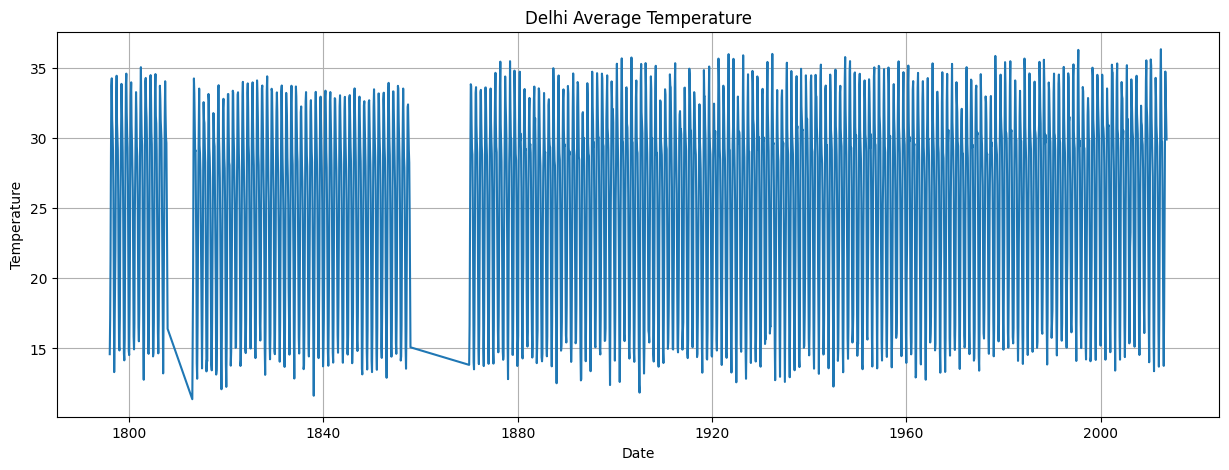

Scaled Data Shape: (4788, 1)
Training Samples: (3830, 1)
Testing Samples: (958, 1)
Training Batches: 118
Testing Batches: 29
Input Shape: (32, 30, 1)
Output Shape: (32, 1)

Original Sequences:
[[1, 2, 3], [4, 5], [6, 7, 8, 9]]

Padded Sequences:
[[0 0 1 2 3]
 [0 0 0 4 5]
 [0 6 7 8 9]]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0317 - mae: 0.1237 - val_loss: 0.0071 - val_mae: 0.0672 - learning_rate: 0.0010
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - loss: 0.0066 - mae: 0.0647 - val_loss: 0.0060 - val_mae: 0.0622 - learning_rate: 0.0010
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0059 - mae: 0.0619 - val_loss: 0.0055 - val_mae: 0.0594 - learning_rate: 0.0010
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0054 - mae: 0.0595 - val_loss: 0.0048 - val_mae: 0.0559 - learning_rate: 0.0010
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0048 - mae: 0.0562 - val_loss: 0.0042 - val_mae: 0.0520 - learning_rate: 0.0010
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0041 - mae: 0.0513 - val_loss: 0.0035 - val_mae: 0.0469 - learning_rate: 0.0010
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.0036 - mae: 0.0475 - val_loss: 0.0033 - val_mae: 0.0452 - learning_rate: 0.0010

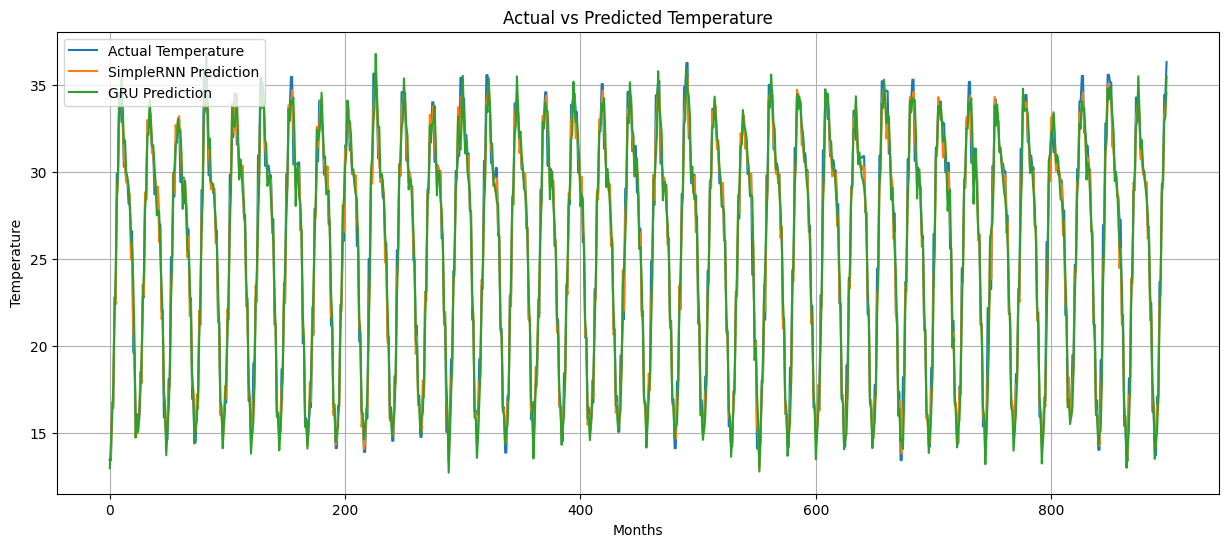

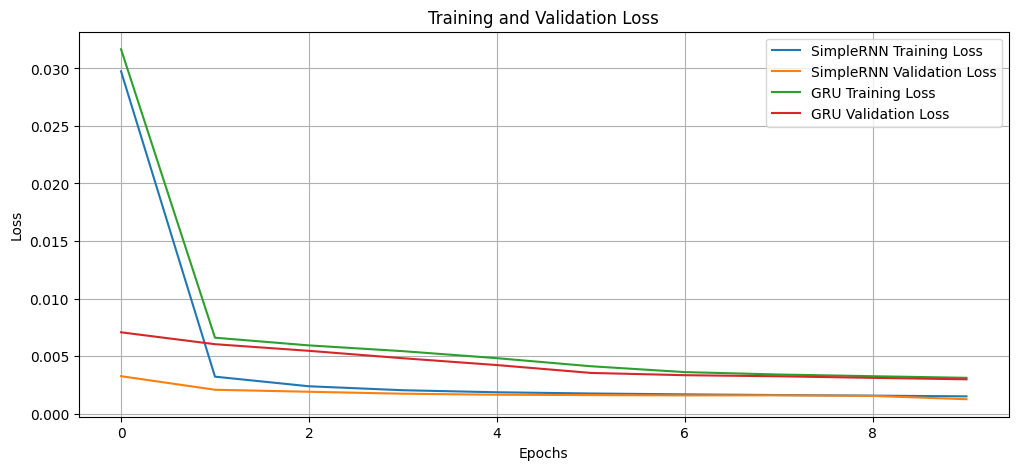


FINAL MODEL COMPARISON
       Model       MSE       MAE
0  SimpleRNN  0.775362  0.639081
1        GRU  1.853192  1.064786

SimpleRNN performs better than GRU

Experiment Completed Successfully!


In [ ]:

# =====================================================
# TASK 7: TIME SERIES FORECASTING USING SimpleRNN AND GRU
# =====================================================

# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import warnings

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.utils import timeseries_dataset_from_array
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense, Input

warnings.filterwarnings("ignore")

print("TensorFlow Version:", tf.__version__)


# 2. DOWNLOAD DATASET

url = "https://raw.githubusercontent.com/urgedata/pythondata/master/examples/climate-change-earth-surface-temperature-data/GlobalLandTemperaturesByMajorCity.csv"

df = pd.read_csv(url)

print("Dataset downloaded successfully!")
print("Dataset Shape:", df.shape)
print(df.head())


# 3. EXPLORE DATASET

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Cities:", df["City"].nunique())


# 4. EXTRACT DELHI TEMPERATURE DATA

city_df = df[
    (df["City"].str.contains("Delhi", case=False, na=False)) &
    (df["Country"] == "India")
].copy()

city_df = city_df.dropna(subset=["AverageTemperature"])

city_df["dt"] = pd.to_datetime(city_df["dt"])

city_df = city_df.sort_values("dt")

city_df.reset_index(drop=True, inplace=True)

print("\nDelhi Dataset:")
print(city_df.head())

print("Delhi Records:", len(city_df))


# 5. EXTRACT TEMPERATURE

temperature = city_df[["AverageTemperature"]]

print("\nTemperature Shape:", temperature.shape)


# 6. VISUALIZE TEMPERATURE

plt.figure(figsize=(15,5))

plt.plot(city_df["dt"], temperature)

plt.title("Delhi Average Temperature")

plt.xlabel("Date")

plt.ylabel("Temperature")

plt.grid(True)

plt.show()


# 7. NORMALIZE DATA

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(temperature)

print("Scaled Data Shape:", scaled_data.shape)


# 8. SPLIT TRAINING AND TESTING DATA

train_size = int(len(scaled_data) * 0.80)

train = scaled_data[:train_size]

test = scaled_data[train_size:]

print("Training Samples:", train.shape)

print("Testing Samples:", test.shape)


# 9. CREATE TIME SERIES SEQUENCES

lookback = 30

batch_size = 32

train_dataset = timeseries_dataset_from_array(

    data=train[:-lookback],

    targets=train[lookback:],

    sequence_length=lookback,

    sequence_stride=1,

    shuffle=False,

    batch_size=batch_size

)

test_dataset = timeseries_dataset_from_array(

    data=test[:-lookback],

    targets=test[lookback:],

    sequence_length=lookback,

    sequence_stride=1,

    shuffle=False,

    batch_size=batch_size

)

print("Training Batches:", len(train_dataset))

print("Testing Batches:", len(test_dataset))


# 10. CHECK INPUT AND OUTPUT SHAPES

for x, y in train_dataset.take(1):

    print("Input Shape:", x.shape)

    print("Output Shape:", y.shape)


# 11. SEQUENCE PADDING

sample_sequences = [

    [1, 2, 3],

    [4, 5],

    [6, 7, 8, 9]

]

padded = pad_sequences(

    sample_sequences,

    maxlen=5,

    padding="pre"

)

print("\nOriginal Sequences:")

print(sample_sequences)

print("\nPadded Sequences:")

print(padded)


# 12. BUILD SimpleRNN MODEL

simple_rnn = Sequential([

    Input(shape=(lookback, 1)),

    SimpleRNN(64, activation="tanh"),

    Dense(32, activation="relu"),

    Dense(1)

])

simple_rnn.summary()


# 13. COMPILE SimpleRNN

simple_rnn.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)


# 14. DEFINE CALLBACKS

callbacks_rnn = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3,

        verbose=1

    )

]


# 15. TRAIN SimpleRNN

history_rnn = simple_rnn.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks_rnn

)


# 16. EVALUATE SimpleRNN

loss_rnn, mae_rnn = simple_rnn.evaluate(

    test_dataset,

    verbose=0

)

print("\nSimpleRNN Loss:", loss_rnn)

print("SimpleRNN MAE:", mae_rnn)


# 17. BUILD GRU MODEL

gru_model = Sequential([

    Input(shape=(lookback, 1)),

    GRU(64, activation="tanh"),

    Dense(32, activation="relu"),

    Dense(1)

])

gru_model.summary()


# 18. COMPILE GRU

gru_model.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)


# 19. DEFINE GRU CALLBACKS

callbacks_gru = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=3,

        verbose=1

    )

]


# 20. TRAIN GRU

history_gru = gru_model.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=10,

    callbacks=callbacks_gru

)


# 21. EVALUATE GRU

loss_gru, mae_gru = gru_model.evaluate(

    test_dataset,

    verbose=0

)

print("\nGRU Loss:", loss_gru)

print("GRU MAE:", mae_gru)


# 22. GENERATE PREDICTIONS

pred_rnn = simple_rnn.predict(test_dataset)

pred_gru = gru_model.predict(test_dataset)

actual = np.concatenate([y.numpy() for x, y in test_dataset])


# 23. CONVERT TO ORIGINAL SCALE

actual = scaler.inverse_transform(actual)

pred_rnn = scaler.inverse_transform(pred_rnn)

pred_gru = scaler.inverse_transform(pred_gru)


# 24. CALCULATE PERFORMANCE METRICS

mse_rnn = mean_squared_error(actual, pred_rnn)

mse_gru = mean_squared_error(actual, pred_gru)

mae_rnn = mean_absolute_error(actual, pred_rnn)

mae_gru = mean_absolute_error(actual, pred_gru)

print("\nSimpleRNN MSE:", mse_rnn)

print("GRU MSE:", mse_gru)

print("SimpleRNN MAE:", mae_rnn)

print("GRU MAE:", mae_gru)


# 25. ACTUAL VS PREDICTED TEMPERATURE

plt.figure(figsize=(15,6))

plt.plot(actual, label="Actual Temperature")

plt.plot(pred_rnn, label="SimpleRNN Prediction")

plt.plot(pred_gru, label="GRU Prediction")

plt.title("Actual vs Predicted Temperature")

plt.xlabel("Months")

plt.ylabel("Temperature")

plt.legend()

plt.grid(True)

plt.show()


# 26. TRAINING AND VALIDATION LOSS

plt.figure(figsize=(12,5))

plt.plot(
    history_rnn.history["loss"],
    label="SimpleRNN Training Loss"
)

plt.plot(
    history_rnn.history["val_loss"],
    label="SimpleRNN Validation Loss"
)

plt.plot(
    history_gru.history["loss"],
    label="GRU Training Loss"
)

plt.plot(
    history_gru.history["val_loss"],
    label="GRU Validation Loss"
)

plt.title("Training and Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()


# 27. FINAL MODEL COMPARISON

comparison = pd.DataFrame({

    "Model": ["SimpleRNN", "GRU"],

    "MSE": [mse_rnn, mse_gru],

    "MAE": [mae_rnn, mae_gru]

})

print("\nFINAL MODEL COMPARISON")

print(comparison)


# 28. EXPERIMENT RESULT

if mse_gru < mse_rnn:

    print("\nGRU performs better than SimpleRNN")

else:

    print("\nSimpleRNN performs better than GRU")


print("\nExperiment Completed Successfully!")

